In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

raw_path = '/content/drive/MyDrive/Project73-Dag/Images'  # โฟลเดอร์ raw images

# นับจำนวนรูปทั้งหมดและแยกตามสายพันธุ์
total_images = 0
breeds = os.listdir(raw_path)

for breed in breeds:
    breed_path = os.path.join(raw_path, breed)
    count = len(os.listdir(breed_path))
    total_images += count
    print(f"  {breed}: {count} images")

print(f"\nรวมทั้งหมด: {total_images} images")

  wire-haired_fox_terrier: 100 images
  Weimaraner: 100 images
  toy_terrier: 100 images
  West_Highland_white_terrier: 100 images
  Walker_hound: 100 images
  whippet: 100 images
  Yorkshire_terrier: 100 images
  toy_poodle: 100 images
  vizsla: 100 images
  Welsh_springer_spaniel: 100 images
  Sussex_spaniel: 100 images
  soft-coated_wheaten_terrier: 100 images
  Staffordshire_bullterrier: 100 images
  standard_schnauzer: 100 images
  standard_poodle: 100 images
  Siberian_husky: 100 images
  Tibetan_mastiff: 100 images
  Tibetan_terrier: 100 images
  silky_terrier: 100 images
  Shih-Tzu: 100 images
  Sealyham_terrier: 100 images
  Shetland_sheepdog: 100 images
  Scottish_deerhound: 100 images
  Saint_Bernard: 100 images
  Saluki: 100 images
  Rhodesian_ridgeback: 100 images
  Rottweiler: 100 images
  Scotch_terrier: 100 images
  Samoyed: 100 images
  schipperke: 100 images
  Pekinese: 100 images
  otterhound: 100 images
  redbone: 100 images
  pug: 100 images
  Pembroke: 100 images


In [ ]:
import os

raw_path = '/content/drive/MyDrive/Project73-Dag/Images'

output_path = '/content/drive/MyDrive/Project73-Dag/dog_split'

breeds = os.listdir(raw_path)

In [ ]:
import os

splits = ['train', 'valid', 'test']

for split in splits:
    for breed in breeds:
        os.makedirs(os.path.join(output_path, split, breed), exist_ok=True)

In [ ]:
import os
import random
import shutil

raw_path = '/content/drive/MyDrive/Project73-Dag/Images'
output_path = '/content/drive/MyDrive/Project73-Dag/dog_split'

splits = ['train', 'valid', 'test']
num_per_split = {'train':70, 'valid':20, 'test':10}
breeds = os.listdir(raw_path)

for split in splits:
    for breed in breeds:
        os.makedirs(os.path.join(output_path, split, breed), exist_ok=True)

for breed in breeds:
    breed_path = os.path.join(raw_path, breed)
    images = os.listdir(breed_path)
    random.shuffle(images)

    start = 0
    for split in splits:
        count = num_per_split[split]
        selected_images = images[start:start+count]
        start += count

        for img in selected_images:
            src = os.path.join(breed_path, img)
            dst = os.path.join(output_path, split, breed, img)
            shutil.copy(src, dst)

In [ ]:
for split in splits:
    split_path = os.path.join(output_path, split)
    total = sum(len(os.listdir(os.path.join(split_path, breed))) for breed in os.listdir(split_path))
    print(f"{split} set: {total} images")

train set: 8330 images
valid set: 2380 images
test set: 1190 images


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (224, 224)
batch_size = 32

train_datagen = ImageDataGenerator(rescale=1./255)
valid_datagen = ImageDataGenerator(rescale=1./255)
test_datagen  = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    os.path.join(output_path, 'train'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

valid_generator = valid_datagen.flow_from_directory(
    os.path.join(output_path, 'valid'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    os.path.join(output_path, 'test'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 8327 images belonging to 119 classes.
Found 2378 images belonging to 119 classes.
Found 1190 images belonging to 119 classes.


In [ ]:
from PIL import Image
import os

output_path = '/content/drive/MyDrive/Project73-Dag/dog_split'

# ชนิดไฟล์ที่จะเปลี่ยน
convert_extensions = ('.webp', '.avif')

print("กำลังเริ่มแปลงไฟล์...")

for split in ['train', 'valid', 'test']:
    split_path = os.path.join(output_path, split)
    if not os.path.exists(split_path): continue

    for breed in os.listdir(split_path):
        breed_path = os.path.join(split_path, breed)
        if os.path.isdir(breed_path):
            for f in os.listdir(breed_path):
                if f.lower().endswith(convert_extensions):
                    old_file = os.path.join(breed_path, f)
                    new_file = os.path.splitext(old_file)[0] + '.jpg'

                    try:
                        with Image.open(old_file) as img:
                            rgb_img = img.convert('RGB')
                            rgb_img.save(new_file, 'JPEG')
                        os.remove(old_file)
                        print(f"Converted & Deleted: {f}")
                    except Exception as e:
                        print(f"Error converting {f}: {e}")

print("แปลงไฟล์เสร็จสิ้น")

กำลังเริ่มแปลงไฟล์...
Converted & Deleted: GettyImages-1177298821-737a7ff28ff64dd59e297d4f40265b51.webp
Converted & Deleted: xolo.1.webp
Converted & Deleted: 669f725437af2497407133.avif
Converted & Deleted: leonberg.webp
Converted & Deleted: landing+page+editA.webp
แปลงไฟล์เสร็จสิ้น


In [ ]:
valid_extensions = ('.jpg', '.jpeg', '.png')

print("กำลังลบไฟล์ขยะ...")
for split in ['train', 'valid', 'test']:
    split_path = os.path.join(output_path, split)
    for breed in os.listdir(split_path):
        breed_path = os.path.join(split_path, breed)
        if os.path.isdir(breed_path):
            for f in os.listdir(breed_path):
                file_full_path = os.path.join(breed_path, f)
                # ถ้าไม่ใช่ไฟล์รูปภาพที่ต้องการ ให้ลบทิ้ง
                if not f.lower().endswith(valid_extensions):
                    os.remove(file_full_path)
                    print(f"Removed non-image file: {f}")

print("ทำความสะอาดข้อมูลเรียบร้อย")

กำลังลบไฟล์ขยะ...
ทำความสะอาดข้อมูลเรียบร้อย


In [ ]:
for split in ['train', 'valid', 'test']:
    split_path = os.path.join(output_path, split)
    total = sum(len(os.listdir(os.path.join(split_path, breed)))
                for breed in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, breed)))
    print(f"{split} set: {total} images")

train set: 8330 images
valid set: 2380 images
test set: 1190 images


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(119, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("สร้างโครงสร้างโมเดลเสร็จเรียบร้อย")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
สร้างโครงสร้างโมเดลเสร็จเรียบร้อย


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = '/content/drive/MyDrive/Project73-Dag/dog_breed_model_v2.h5'

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

history = model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=10,
    callbacks=[checkpoint]
)

print(f"เทรนเสร็จสมบูรณ์! ไฟล์โมเดลอยู่ที่: {checkpoint_path}")

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3981 - loss: 2.7188
Epoch 1: val_accuracy improved from -inf to 0.76577, saving model to /content/drive/MyDrive/Project73-Dag/dog_breed_model_v2.h5


261/261 ━━━━━━━━━━━━━━━━━━━━ 519s 2s/step - accuracy: 0.3988 - loss: 2.7148 - val_accuracy: 0.7658 - val_loss: 0.8163
Epoch 2/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8358 - loss: 0.5734
Epoch 2: val_accuracy improved from 0.76577 to 0.77502, saving model to /content/drive/MyDrive/Project73-Dag/dog_breed_model_v2.h5


261/261 ━━━━━━━━━━━━━━━━━━━━ 469s 2s/step - accuracy: 0.8357 - loss: 0.5734 - val_accuracy: 0.7750 - val_loss: 0.7171
Epoch 3/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8923 - loss: 0.3829
Epoch 3: val_accuracy improved from 0.77502 to 0.79016, saving model to /content/drive/MyDrive/Project73-Dag/dog_breed_model_v2.h5


261/261 ━━━━━━━━━━━━━━━━━━━━ 465s 2s/step - accuracy: 0.8923 - loss: 0.3829 - val_accuracy: 0.7902 - val_loss: 0.6692
Epoch 4/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9309 - loss: 0.2775
Epoch 4: val_accuracy did not improve from 0.79016
261/261 ━━━━━━━━━━━━━━━━━━━━ 497s 2s/step - accuracy: 0.9309 - loss: 0.2775 - val_accuracy: 0.7897 - val_loss: 0.6587
Epoch 5/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9500 - loss: 0.2108
Epoch 5: val_accuracy improved from 0.79016 to 0.79815, saving model to /content/drive/MyDrive/Project73-Dag/dog_breed_model_v2.h5


261/261 ━━━━━━━━━━━━━━━━━━━━ 447s 2s/step - accuracy: 0.9500 - loss: 0.2109 - val_accuracy: 0.7981 - val_loss: 0.6486
Epoch 6/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9662 - loss: 0.1603
Epoch 6: val_accuracy did not improve from 0.79815
261/261 ━━━━━━━━━━━━━━━━━━━━ 496s 2s/step - accuracy: 0.9662 - loss: 0.1603 - val_accuracy: 0.7956 - val_loss: 0.6449
Epoch 7/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9796 - loss: 0.1284
Epoch 7: val_accuracy did not improve from 0.79815
261/261 ━━━━━━━━━━━━━━━━━━━━ 467s 2s/step - accuracy: 0.9796 - loss: 0.1284 - val_accuracy: 0.7965 - val_loss: 0.6480
Epoch 8/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9824 - loss: 0.1106
Epoch 8: val_accuracy did not improve from 0.79815
261/261 ━━━━━━━━━━━━━━━━━━━━ 456s 2s/step - accuracy: 0.9824 - loss: 0.1106 - val_accuracy: 0.7960 - val_loss: 0.6532
Epoch 9/10
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9857 - loss: 0.0941
Epoch 9: val_accuracy did not impro

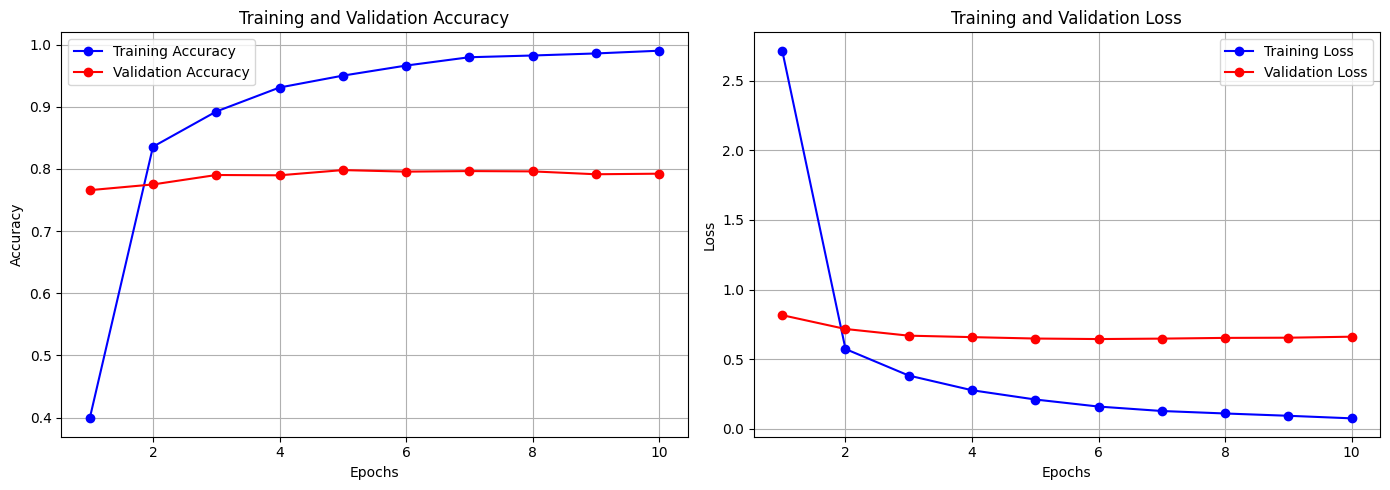

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, 11)

train_acc = [0.3988, 0.8357, 0.8923, 0.9309, 0.9500, 0.9662, 0.9796, 0.9824, 0.9857, 0.9901]
val_acc = [0.7658, 0.7750, 0.7902, 0.7897, 0.7981, 0.7956, 0.7965, 0.7960, 0.7914, 0.7923]

train_loss = [2.7148, 0.5734, 0.3829, 0.2775, 0.2109, 0.1603, 0.1284, 0.1106, 0.0941, 0.0757]
val_loss = [0.8163, 0.7171, 0.6692, 0.6587, 0.6486, 0.6449, 0.6480, 0.6532, 0.6546, 0.6618]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc, 'b-o', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r-o', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, 'b-o', label='Training Loss')
plt.plot(epochs, val_loss, 'r-o', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import os

output_path = '/content/drive/MyDrive/Project73-Dag/dog_split'

class_names = sorted([d for d in os.listdir(os.path.join(output_path, 'train'))
                     if os.path.isdir(os.path.join(output_path, 'train', d))])

labels_save_path = '/content/drive/MyDrive/Project73-Dag/dog_labels.txt'
with open(labels_save_path, 'w') as f:
    for breed in class_names:
        f.write(f"{breed}\n")

print(f"บันทึกรายชื่อ {len(class_names)} สายพันธุ์")
print(f"ไฟล์ถูกเก็บไว้ที่: {labels_save_path}")

if len(class_names) == 119:
    print("จำนวนสายพันธุ์ 119 คลาส")
else:
    print(f"พบ {len(class_names)} สายพันธุ์")

บันทึกรายชื่อ 119 สายพันธุ์
ไฟล์ถูกเก็บไว้ที่: /content/drive/MyDrive/Project73-Dag/dog_labels.txt
จำนวนสายพันธุ์ 119 คลาส


In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import drive, files
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image

MODEL_PATH = '/content/drive/MyDrive/Modeldog/สำเนาของ dog_breed_model_v2.h5'
LABELS_PATH = '/content/drive/MyDrive/Modeldog/สำเนาของ dog_labels.txt'

if os.path.exists(MODEL_PATH) and os.path.exists(LABELS_PATH):
    model = load_model(MODEL_PATH)
    with open(LABELS_PATH, 'r') as f:
        class_names = [line.strip() for line in f.readlines()]
    print(f"โหลดโมเดลสำเร็จ")
else:
    print("ไม่พบไฟล์")

โหลดโมเดลสำเร็จ


In [ ]:
def predict_now():
    uploaded = files.upload()
    for fn in uploaded.keys():
        img = image.load_img(fn, target_size=(224, 224))
        img_array = image.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        preds = model.predict(img_array, verbose=0)
        idx = np.argmax(preds[0])
        conf = preds[0][idx] * 100

        plt.imshow(img)
        plt.title(f"Predict: {class_names[idx]}\nConfidence: {conf:.2f}%")
        plt.axis('off')
        plt.show()

Saving n02111889_1363_jpg.rf.15dea6c217b1c68ea614f301f351b91e.jpg to n02111889_1363_jpg.rf.15dea6c217b1c68ea614f301f351b91e.jpg


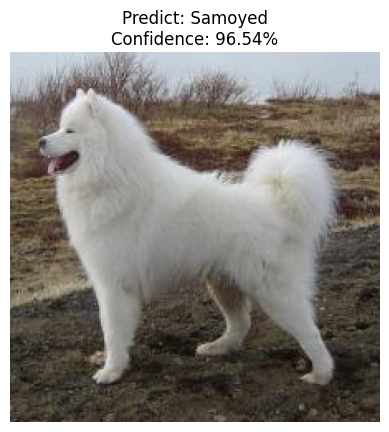

In [ ]:
        predict_now()